# Week 8: K-Nearest Neighbors and Distance Metrics

## Objective
Evaluate whether K-Nearest Neighbors (KNN) can improve predictions
of NBA game totals compared with sportsbook expectations.

This analysis will examine:
- KNN regression for predicting combined game scores.
- KNN classification for predicting Over/Under outcomes.
- Euclidean, Manhattan, and Chebyshev distance metrics.
- The impact of the number of neighbors (K).
- Cross-validation, feature scaling, and overfitting.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, GridSearchCV, TimeSeriesSplit, cross_validate
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [14]:
df = pd.read_csv(
    "../data/processed/merged_games_betting.csv",
    low_memory=False
)

print("Dataset shape:", df.shape)

# Verify the main columns needed for Week 8
features = ["total", "spread", "moneyline_home", "moneyline_away"]

print("\nRequired columns:")
print(df[features + ["actual_total"]].dtypes)

print("\nMissing values:")
print(df[features + ["actual_total"]].isna().sum())

print("\nPotential date columns:")
print([col for col in df.columns if "date" in col.lower()])

df[features + ["actual_total"]].head()

Dataset shape: (21965, 54)

Required columns:
total             float64
spread            float64
moneyline_home    float64
moneyline_away    float64
actual_total        int64
dtype: object

Missing values:
total                0
spread               3
moneyline_home    3289
moneyline_away    3289
actual_total         0
dtype: int64

Potential date columns:
['gameDateTimeEst', 'gameDate', 'date']


,total,spread,moneyline_home,moneyline_away,actual_total
0,222.5,5.5,NaN,NaN,199
1,223.5,8.5,NaN,NaN,229
2,227.5,6.5,NaN,NaN,215
3,225.5,4.5,NaN,NaN,223
4,227.5,11.5,NaN,NaN,230


## Data Preparation and Chronological Validation

Before training KNN models, the dataset is examined for missing
values and chronological consistency.

This analysis will evaluate models on later games to better simulate real-world predictions and reduce the risk of temporal leakage.

In [15]:
date_cols = ["gameDateTimeEst", "gameDate", "date"]

print("Sample date values:")
display(df[date_cols].head(10))

for col in date_cols:
    parsed = pd.to_datetime(df[col], errors="coerce", utc=True)

    print(f"\n{col}")
    print("Valid dates:", parsed.notna().sum())
    print("Missing/invalid dates:", parsed.isna().sum())
    print("Earliest date:", parsed.min())
    print("Latest date:", parsed.max())

Sample date values:


,gameDateTimeEst,gameDate,date
0,2025-06-19 20:30:00,2025-06-19,2025-06-19
1,2025-06-16 20:30:00,2025-06-16,2025-06-16
2,2025-06-13 20:30:00,2025-06-13,2025-06-13
3,2025-06-11 20:30:00,2025-06-11,2025-06-11
4,2025-06-08 20:00:00,2025-06-08,2025-06-08
5,2025-06-05 20:30:00,2025-06-05,2025-06-05
6,2025-05-31 20:00:00,2025-05-31,2025-05-31
7,2025-05-29 20:00:00,2025-05-29,2025-05-29
8,2025-05-28 20:30:00,2025-05-28,2025-05-28
9,2025-05-27 20:00:00,2025-05-27,2025-05-27



gameDateTimeEst
Valid dates: 21965
Missing/invalid dates: 0
Earliest date: 2007-10-30 20:00:00+00:00
Latest date: 2025-06-19 20:30:00+00:00

gameDate
Valid dates: 21965
Missing/invalid dates: 0
Earliest date: 2007-10-30 00:00:00+00:00
Latest date: 2025-06-19 00:00:00+00:00

date
Valid dates: 21965
Missing/invalid dates: 0
Earliest date: 2007-10-30 00:00:00+00:00
Latest date: 2025-06-19 00:00:00+00:00


## Chronological Train/Test Split

The dataset is sorted chronologically to simulate real-world NBA predictions. Earlier games are used for training, while the most recent 20% are reserved for testing.

This approach reduces the risk of temporal leakage and allows the models to be evaluated on future observations.

The sportsbook total serves as the benchmark for KNN regression.

In [16]:
df["game_date"] = pd.to_datetime(df["gameDate"])

df_sorted = df.sort_values("game_date").reset_index(drop=True)

split_idx = int(len(df_sorted) * 0.80)
cutoff_date = df_sorted.loc[split_idx, "game_date"]

train_df = df_sorted[df_sorted["game_date"] < cutoff_date].copy()
test_df = df_sorted[df_sorted["game_date"] >= cutoff_date].copy()

print("Training games:", len(train_df))
print("Testing games:", len(test_df))

print("\nTraining period:")
print(train_df["game_date"].min(), "to", train_df["game_date"].max())

print("\nTesting period:")
print(test_df["game_date"].min(), "to", test_df["game_date"].max())

sportsbook_mae = mean_absolute_error(
    test_df["actual_total"],
    test_df["total"]
)

sportsbook_rmse = np.sqrt(
    mean_squared_error(
        test_df["actual_total"],
        test_df["total"]
    )
)

print("\nSportsbook Benchmark (Test Set)")
print(f"MAE: {sportsbook_mae:.4f}")
print(f"RMSE: {sportsbook_rmse:.4f}")

Training games: 17568
Testing games: 4397

Training period:
2007-10-30 00:00:00 to 2022-02-16 00:00:00

Testing period:
2022-02-17 00:00:00 to 2025-06-19 00:00:00

Sportsbook Benchmark (Test Set)
MAE: 14.1386
RMSE: 17.8186


## KNN Regression: Initial Model

The first KNN regression model uses sportsbook totals, point spreads,
and home and away moneylines to predict actual combined game scores.

Missing predictor values are imputed using training-data medians,
and missingness indicators are retained. Features are standardized
because KNN is sensitive to differences in numerical scales.

The initial model uses 15 neighbors, uniform weighting, and
Euclidean distance. Later experiments will tune these settings
using time-aware cross-validation.

In [17]:
features = ["total", "spread", "moneyline_home", "moneyline_away"]

X_train = train_df[features]
X_test = test_df[features]

y_train = train_df["actual_total"]
y_test = test_df["actual_total"]

knn_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsRegressor(
        n_neighbors=15,
        weights="uniform",
        metric="euclidean"
    ))
])

knn_pipeline.fit(X_train, y_train)

y_train_pred = knn_pipeline.predict(X_train)
y_test_pred = knn_pipeline.predict(X_test)

results = pd.DataFrame({
    "Model": ["Sportsbook Benchmark", "KNN (K=15, Euclidean)"],
    "Test MAE": [
        sportsbook_mae,
        mean_absolute_error(y_test, y_test_pred)
    ],
    "Test RMSE": [
        sportsbook_rmse,
        np.sqrt(mean_squared_error(y_test, y_test_pred))
    ]
})

print("KNN Training MAE:",
      round(mean_absolute_error(y_train, y_train_pred), 4))

display(results.round(4))

KNN Training MAE: 13.5357


,Model,Test MAE,Test RMSE
0,Sportsbook Benchmark,14.1386,17.8186
1,"KNN (K=15, Euclidean)",15.3041,19.3666


## Comparing KNN Distance Metrics

KNN predictions depend on how distances between NBA games are calculated.

Three metrics are compared:
- Euclidean: Measures straight-line distance.
- Manhattan: Sums absolute differences across predictors.
- Chebyshev: Measures the largest difference across predictors.

To avoid tuning on the test set, the metrics are evaluated using
time-aware cross-validation on the training data.

The number of neighbors is fixed at K=15 for this comparison.

In [18]:
unique_dates = np.sort(train_df["game_date"].unique())

tscv = TimeSeriesSplit(n_splits=4)

cv_splits = []

for train_dates_idx, val_dates_idx in tscv.split(unique_dates):

    train_dates = unique_dates[train_dates_idx]
    val_dates = unique_dates[val_dates_idx]

    train_idx = np.flatnonzero(
        train_df["game_date"].isin(train_dates).to_numpy()
    )

    val_idx = np.flatnonzero(
        train_df["game_date"].isin(val_dates).to_numpy()
    )

    cv_splits.append((train_idx, val_idx))

distance_metrics = ["euclidean", "manhattan", "chebyshev"]

metric_results = []

for metric in distance_metrics:

    pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            add_indicator=True
        )),
        ("scaler", StandardScaler()),
        ("knn", KNeighborsRegressor(
            n_neighbors=15,
            metric=metric,
            weights="uniform"
        ))
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv_splits,
        scoring="neg_mean_absolute_error",
        return_train_score=True
    )

    metric_results.append({
        "Distance Metric": metric,
        "Training MAE": -scores["train_score"].mean(),
        "CV MAE": -scores["test_score"].mean()
    })

metric_results_df = pd.DataFrame(metric_results)

display(
    metric_results_df.sort_values("CV MAE").round(4)
)

,Distance Metric,Training MAE,CV MAE
0,euclidean,13.3687,14.4667
2,chebyshev,13.3681,14.4760
1,manhattan,13.4163,14.4904


## KNN Hyperparameter Tuning

GridSearchCV is used to optimize the number of neighbors, distance
metric, and neighbor weighting.

Larger K values generally produce smoother predictions, potentially
reducing overfitting but increasing the risk of underfitting.

The search uses chronological cross-validation and minimizes MAE.
All preprocessing is performed within the pipeline to avoid
data leakage.

In [19]:
cv_sportsbook_mae = np.mean([
    mean_absolute_error(
        y_train.iloc[val_idx],
        X_train.iloc[val_idx]["total"]
    )
    for _, val_idx in cv_splits
])

print(f"Sportsbook CV MAE: {cv_sportsbook_mae:.4f}")

knn_tuning_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsRegressor())
])

param_grid = {
    "knn__n_neighbors": [5, 15, 30, 60, 100],
    "knn__metric": ["euclidean", "manhattan", "chebyshev"],
    "knn__weights": ["uniform", "distance"]
}

knn_grid = GridSearchCV(
    estimator=knn_tuning_pipeline,
    param_grid=param_grid,
    cv=cv_splits,
    scoring="neg_mean_absolute_error",
    n_jobs=2,
    return_train_score=True
)

knn_grid.fit(X_train, y_train)

print("\nBest parameters:")
print(knn_grid.best_params_)

print("\nBest KNN CV MAE:",
      round(-knn_grid.best_score_, 4))

print("Sportsbook CV MAE:",
      round(cv_sportsbook_mae, 4))

Sportsbook CV MAE: 13.9585

Best parameters:
{'knn__metric': 'chebyshev', 'knn__n_neighbors': 100, 'knn__weights': 'uniform'}

Best KNN CV MAE: 14.1845
Sportsbook CV MAE: 13.9585


## Final KNN Regression Evaluation

The best KNN model selected through chronological cross-validation
is evaluated on the held-out test set.

Performance is compared against the sportsbook benchmark using
MAE and RMSE. Training error is also examined to identify
potential overfitting.

In [20]:
best_knn = knn_grid.best_estimator_

# Predictions
knn_train_pred = best_knn.predict(X_train)
knn_test_pred = best_knn.predict(X_test)

knn_train_mae = mean_absolute_error(y_train, knn_train_pred)
knn_test_mae = mean_absolute_error(y_test, knn_test_pred)
knn_test_rmse = np.sqrt(mean_squared_error(y_test, knn_test_pred))

final_results = pd.DataFrame({
    "Model": [
        "Sportsbook Benchmark",
        "Initial KNN (K=15, Euclidean)",
        "Optimized KNN"
    ],
    "Test MAE": [
        sportsbook_mae,
        mean_absolute_error(y_test, y_test_pred),
        knn_test_mae
    ],
    "Test RMSE": [
        sportsbook_rmse,
        np.sqrt(mean_squared_error(y_test, y_test_pred)),
        knn_test_rmse
    ]
})

print("Optimized KNN Training MAE:", round(knn_train_mae, 4))
print("Optimized KNN Testing MAE:", round(knn_test_mae, 4))
print("Train-Test MAE Gap:", round(knn_test_mae - knn_train_mae, 4))

display(final_results.round(4))

Optimized KNN Training MAE: 13.9481
Optimized KNN Testing MAE: 26.6475
Train-Test MAE Gap: 12.6994


,Model,Test MAE,Test RMSE
0,Sportsbook Benchmark,14.1386,17.8186
1,"Initial KNN (K=15, Euclidean)",15.3041,19.3666
2,Optimized KNN,26.6475,32.5281


## Investigating KNN Generalization and Distribution Shift

The optimized KNN model performed substantially worse on recent
NBA games than during historical cross-validation.

This section investigates whether differences in scoring averages,
sportsbook totals, missing moneylines, or prediction behavior
could help explain the performance decline.

In [21]:
comparison = pd.DataFrame({
    "Training": [
        y_train.mean(),
        X_train["total"].mean(),
        X_train["spread"].mean(),
        X_train["moneyline_home"].isna().mean() * 100,
        knn_train_pred.mean()
    ],
    "Testing": [
        y_test.mean(),
        X_test["total"].mean(),
        X_test["spread"].mean(),
        X_test["moneyline_home"].isna().mean() * 100,
        knn_test_pred.mean()
    ]
}, index=[
    "Average Actual Total",
    "Average Sportsbook Total",
    "Average Spread",
    "Missing Home Moneylines (%)",
    "Average Optimized KNN Prediction"
])

display(comparison.round(2))

test_analysis = test_df[["game_date", "actual_total", "total"]].copy()

test_analysis["Year"] = test_analysis["game_date"].dt.year
test_analysis["Sportsbook Error"] = abs(
    test_analysis["actual_total"] - test_analysis["total"]
)
test_analysis["Initial KNN Error"] = abs(
    test_analysis["actual_total"] - y_test_pred
)
test_analysis["Optimized KNN Error"] = abs(
    test_analysis["actual_total"] - knn_test_pred
)

yearly_results = test_analysis.groupby("Year")[
    ["Sportsbook Error", "Initial KNN Error", "Optimized KNN Error"]
].mean()

display(yearly_results.round(4))

,Training,Testing
Average Actual Total,207.40,227.42
Average Sportsbook Total,207.09,226.83
Average Spread,6.09,6.36
Missing Home Moneylines (%),0.01,74.78
Average Optimized KNN Prediction,207.39,204.53


,Sportsbook Error,Initial KNN Error,Optimized KNN Error
Year,,,
2022,13.9455,14.3239,13.8937
2023,14.0347,15.6100,31.1171
2024,14.6546,15.5145,29.1787
2025,13.7029,15.6774,31.0930


## KNN Robustness Analysis: Excluding Moneylines

The initial optimized KNN model showed a substantial decline in
performance on recent NBA games. Exploratory analysis revealed that
moneyline availability differed considerably between training and
testing periods.

To investigate whether missing moneyline information contributed
to this decline, KNN regression is repeated using only sportsbook
totals and point spreads.

The same chronological cross-validation strategy is used to tune
K, distance metrics, and weighting methods.

Because this experiment was motivated by examining test-set
results, it is treated as a diagnostic robustness analysis rather
than a new independent evaluation.

In [22]:
robust_features = ["total", "spread"]

X_train_robust = train_df[robust_features]
X_test_robust = test_df[robust_features]

robust_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsRegressor())
])

robust_grid = GridSearchCV(
    estimator=robust_pipeline,
    param_grid=param_grid,
    cv=cv_splits,
    scoring="neg_mean_absolute_error",
    n_jobs=2,
    return_train_score=True
)

robust_grid.fit(X_train_robust, y_train)

robust_model = robust_grid.best_estimator_

robust_train_pred = robust_model.predict(X_train_robust)
robust_test_pred = robust_model.predict(X_test_robust)

robust_train_mae = mean_absolute_error(
    y_train, robust_train_pred
)

robust_test_mae = mean_absolute_error(
    y_test, robust_test_pred
)

robust_test_rmse = np.sqrt(
    mean_squared_error(y_test, robust_test_pred)
)

print("Best parameters:", robust_grid.best_params_)
print("Best CV MAE:", round(-robust_grid.best_score_, 4))
print("Training MAE:", round(robust_train_mae, 4))

comparison = pd.DataFrame({
    "Model": [
        "Sportsbook Benchmark",
        "Original Optimized KNN",
        "KNN Without Moneylines"
    ],
    "Test MAE": [
        sportsbook_mae,
        knn_test_mae,
        robust_test_mae
    ],
    "Test RMSE": [
        sportsbook_rmse,
        knn_test_rmse,
        robust_test_rmse
    ]
})

display(comparison.round(4))

Best parameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 100, 'knn__weights': 'uniform'}
Best CV MAE: 14.0795
Training MAE: 13.8859


,Model,Test MAE,Test RMSE
0,Sportsbook Benchmark,14.1386,17.8186
1,Original Optimized KNN,26.6475,32.5281
2,KNN Without Moneylines,14.2456,17.9793


## Visualizing Missing-Data Distribution Shift

Moneyline availability changed significantly between the historical
training period and the recent testing period.

This visualization helps explain why a distance-based model might
perform poorly when feature availability changes over time.

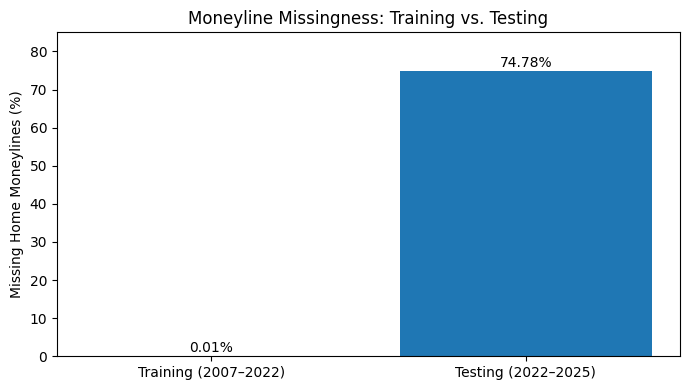

In [23]:
missing_pct = [
    X_train["moneyline_home"].isna().mean() * 100,
    X_test["moneyline_home"].isna().mean() * 100
]

labels = ["Training (2007–2022)", "Testing (2022–2025)"]

plt.figure(figsize=(7, 4))

bars = plt.bar(labels, missing_pct)

plt.ylabel("Missing Home Moneylines (%)")
plt.title("Moneyline Missingness: Training vs. Testing")
plt.ylim(0, 85)

for bar, value in zip(bars, missing_pct):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()

Path("../figures").mkdir(parents=True, exist_ok=True)

plt.savefig(
    "../figures/week08_moneyline_missingness.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## KNN Classification: Over/Under Prediction

KNN classification is used to predict whether an NBA game's
combined score finishes Over or Under the sportsbook total.

The model uses sportsbook totals and point spreads as predictors.

Games that finish exactly on the sportsbook total (pushes)
are excluded.

Classification models will be evaluated using accuracy,
precision, recall, F1 score, and ROC AUC.

In [24]:
train_class = train_df[
    train_df["actual_total"] != train_df["total"]
].copy()

test_class = test_df[
    test_df["actual_total"] != test_df["total"]
].copy()


train_class["over"] = (
    train_class["actual_total"] > train_class["total"]
).astype(int)

test_class["over"] = (
    test_class["actual_total"] > test_class["total"]
).astype(int)

class_features = ["total", "spread"]

X_train_cls = train_class[class_features]
X_test_cls = test_class[class_features]

y_train_cls = train_class["over"]
y_test_cls = test_class["over"]

majority_class = int(y_train_cls.mode().iloc[0])

baseline_predictions = np.full(
    len(y_test_cls),
    majority_class
)

baseline_accuracy = accuracy_score(
    y_test_cls,
    baseline_predictions
)

print("Training games:", len(train_class))
print("Testing games:", len(test_class))

print("\nTraining class distribution:")
print(y_train_cls.value_counts(normalize=True).round(4))

print("\nTesting class distribution:")
print(y_test_cls.value_counts(normalize=True).round(4))

print("\nMajority class:", majority_class)
print("Majority-class test accuracy:", round(baseline_accuracy, 4))

Training games: 17331
Testing games: 4381

Training class distribution:
over
0    0.5022
1    0.4978
Name: proportion, dtype: float64

Testing class distribution:
over
1    0.5081
0    0.4919
Name: proportion, dtype: float64

Majority class: 0
Majority-class test accuracy: 0.4919


In [25]:
knn_classifier = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(
        n_neighbors=15,
        metric="euclidean",
        weights="uniform"
    ))
])

# Train
knn_classifier.fit(X_train_cls, y_train_cls)

# Predictions
train_cls_pred = knn_classifier.predict(X_train_cls)
test_cls_pred = knn_classifier.predict(X_test_cls)

# Predicted probabilities for ROC AUC
test_cls_proba = knn_classifier.predict_proba(X_test_cls)[:, 1]

# Evaluate
classification_results = pd.DataFrame({
    "Model": ["Majority Baseline", "KNN (K=15, Euclidean)"],
    "Accuracy": [
        baseline_accuracy,
        accuracy_score(y_test_cls, test_cls_pred)
    ],
    "Precision": [
        precision_score(y_test_cls, baseline_predictions, zero_division=0),
        precision_score(y_test_cls, test_cls_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test_cls, baseline_predictions, zero_division=0),
        recall_score(y_test_cls, test_cls_pred, zero_division=0)
    ],
    "F1": [
        f1_score(y_test_cls, baseline_predictions, zero_division=0),
        f1_score(y_test_cls, test_cls_pred, zero_division=0)
    ],
    "ROC AUC": [
        0.5,
        roc_auc_score(y_test_cls, test_cls_proba)
    ]
})

print(
    "Training Accuracy:",
    round(accuracy_score(y_train_cls, train_cls_pred), 4)
)

display(classification_results.round(4))

Training Accuracy: 0.6012


,Model,Accuracy,Precision,Recall,F1,ROC AUC
0,Majority Baseline,0.4919,0.0000,0.0000,0.0000,0.500
1,"KNN (K=15, Euclidean)",0.5001,0.5085,0.4865,0.4972,0.502


## KNN Classification Hyperparameter Tuning

KNN classification is tuned using chronological cross-validation.

The following hyperparameters are evaluated:
- Number of neighbors (K)
- Distance metric: Euclidean, Manhattan, Chebyshev
- Neighbor weighting: Uniform or distance-based

ROC AUC is used to select the best configuration.

Chronological cross-validation helps evaluate generalization
while keeping the final test period separate from tuning.

In [26]:
# Rebuild CV folds after removing pushes
unique_class_dates = np.sort(train_class["game_date"].unique())

tscv_class = TimeSeriesSplit(n_splits=4)
class_cv_splits = []

for train_dates_idx, val_dates_idx in tscv_class.split(unique_class_dates):

    train_dates = unique_class_dates[train_dates_idx]
    val_dates = unique_class_dates[val_dates_idx]

    train_idx = np.flatnonzero(
        train_class["game_date"].isin(train_dates).to_numpy()
    )

    val_idx = np.flatnonzero(
        train_class["game_date"].isin(val_dates).to_numpy()
    )

    class_cv_splits.append((train_idx, val_idx))


# KNN classification pipeline
knn_class_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

# Hyperparameter grid
class_param_grid = {
    "knn__n_neighbors": [5, 15, 30, 60, 100],
    "knn__metric": ["euclidean", "manhattan", "chebyshev"],
    "knn__weights": ["uniform", "distance"]
}

# Cross-validation tuning
knn_class_grid = GridSearchCV(
    estimator=knn_class_pipeline,
    param_grid=class_param_grid,
    scoring="roc_auc",
    cv=class_cv_splits,
    n_jobs=2,
    return_train_score=True
)

knn_class_grid.fit(X_train_cls, y_train_cls)

print("Best parameters:")
print(knn_class_grid.best_params_)

print("\nBest Cross-Validation ROC AUC:")
print(round(knn_class_grid.best_score_, 4))

Best parameters:
{'knn__metric': 'chebyshev', 'knn__n_neighbors': 60, 'knn__weights': 'uniform'}

Best Cross-Validation ROC AUC:
0.507


## Final KNN Classification Evaluation

The optimized KNN classifier is evaluated on the held-out
2022–2025 NBA games.

Performance is compared against the training-majority baseline
and the initial KNN classifier using accuracy, precision,
recall, F1 score, and ROC AUC.

Training and testing accuracy are also compared to investigate
whether hyperparameter tuning reduced overfitting.

In [27]:
# Retrieve the best classifier from GridSearchCV
best_knn_classifier = knn_class_grid.best_estimator_

# Predictions
best_train_pred = best_knn_classifier.predict(X_train_cls)
best_test_pred = best_knn_classifier.predict(X_test_cls)

# Probabilities for ROC AUC
best_test_proba = best_knn_classifier.predict_proba(X_test_cls)[:, 1]

# Calculate training and testing accuracy
best_train_acc = accuracy_score(y_train_cls, best_train_pred)
best_test_acc = accuracy_score(y_test_cls, best_test_pred)

print("Optimized KNN Training Accuracy:", round(best_train_acc, 4))
print("Optimized KNN Testing Accuracy:", round(best_test_acc, 4))
print("Train-Test Accuracy Gap:", round(best_train_acc - best_test_acc, 4))

# Final comparison table
final_class_results = pd.DataFrame({
    "Model": [
        "Majority Baseline",
        "Initial KNN (K=15)",
        "Optimized KNN (K=60)"
    ],
    "Accuracy": [
        baseline_accuracy,
        accuracy_score(y_test_cls, test_cls_pred),
        best_test_acc
    ],
    "Precision": [
        0.0,
        precision_score(y_test_cls, test_cls_pred, zero_division=0),
        precision_score(y_test_cls, best_test_pred, zero_division=0)
    ],
    "Recall": [
        0.0,
        recall_score(y_test_cls, test_cls_pred, zero_division=0),
        recall_score(y_test_cls, best_test_pred, zero_division=0)
    ],
    "F1": [
        0.0,
        f1_score(y_test_cls, test_cls_pred, zero_division=0),
        f1_score(y_test_cls, best_test_pred, zero_division=0)
    ],
    "ROC AUC": [
        0.5,
        roc_auc_score(y_test_cls, test_cls_proba),
        roc_auc_score(y_test_cls, best_test_proba)
    ]
})

display(final_class_results.round(4))

Optimized KNN Training Accuracy: 0.5499
Optimized KNN Testing Accuracy: 0.5065
Train-Test Accuracy Gap: 0.0434


,Model,Accuracy,Precision,Recall,F1,ROC AUC
0,Majority Baseline,0.4919,0.0000,0.0000,0.0000,0.5000
1,Initial KNN (K=15),0.5001,0.5085,0.4865,0.4972,0.5020
2,Optimized KNN (K=60),0.5065,0.5149,0.4969,0.5057,0.5126


## Advanced KNN: Historical Team Form Features

This experiment incorporates lagged team scoring, defensive
performance, recent results relative to sportsbook totals,
and rest days.

All historical statistics are computed using games played
before the prediction date to prevent target leakage.

The goal is to determine whether recent basketball performance
provides additional information for KNN classification.

In [30]:
# Identify team and score columns
def find_column(candidates):
    for col in candidates:
        if col in df_sorted.columns:
            return col
    raise KeyError(f"None of these columns found: {candidates}")

home_col = "hometeamId"
away_col = "awayteamId"

home_score_col = "homeScore"
away_score_col = "awayScore"

# Prepare the complete chronological dataset
games = df_sorted.copy()

games[home_col] = games[home_col].astype(str)
games[away_col] = games[away_col].astype(str)

games["score_residual"] = games["actual_total"] - games["total"]

# Convert each game into two team observations
home_games = pd.DataFrame({
    "team": games[home_col],
    "game_date": games["game_date"],
    "points_for": games[home_score_col],
    "points_against": games[away_score_col],
    "residual": games["score_residual"]
})

away_games = pd.DataFrame({
    "team": games[away_col],
    "game_date": games["game_date"],
    "points_for": games[away_score_col],
    "points_against": games[home_score_col],
    "residual": games["score_residual"]
})

team_games = pd.concat(
    [home_games, away_games],
    ignore_index=True
)

# Aggregate by team and date to prevent same-day leakage
daily = (
    team_games
    .groupby(["team", "game_date"], as_index=False)
    .agg({
        "points_for": "mean",
        "points_against": "mean",
        "residual": "mean"
    })
    .sort_values(["team", "game_date"])
    .reset_index(drop=True)
)

# Calculate lagged rolling statistics
for window in [5, 10]:
    for col in ["points_for", "points_against", "residual"]:

        daily[f"{col}_{window}"] = (
            daily.groupby("team")[col]
            .transform(
                lambda x: x.shift(1)
                .rolling(window, min_periods=3)
                .mean()
            )
        )

# Rest days before each game
previous_date = daily.groupby("team")["game_date"].shift(1)

daily["rest_days"] = (
    (daily["game_date"] - previous_date).dt.days - 1
).clip(lower=0, upper=7)

# Merge historical stats onto home and away teams
history_cols = [
    "points_for_5", "points_against_5", "residual_5",
    "points_for_10", "points_against_10", "residual_10",
    "rest_days"
]

home_history = daily[
    ["team", "game_date"] + history_cols
].rename(columns={
    "team": home_col,
    **{col: f"home_{col}" for col in history_cols}
})

away_history = daily[
    ["team", "game_date"] + history_cols
].rename(columns={
    "team": away_col,
    **{col: f"away_{col}" for col in history_cols}
})

games = games.merge(
    home_history,
    on=[home_col, "game_date"],
    how="left",
    validate="many_to_one"
)

games = games.merge(
    away_history,
    on=[away_col, "game_date"],
    how="left",
    validate="many_to_one"
)

# Construct a scoring estimate from recent team performance
for window in [5, 10]:

    games[f"expected_total_{window}"] = (
        games[f"home_points_for_{window}"]
        + games[f"away_points_against_{window}"]
        + games[f"away_points_for_{window}"]
        + games[f"home_points_against_{window}"]
    ) / 2

    # Recent team-based estimate minus sportsbook expectation
    games[f"scoring_edge_{window}"] = (
        games[f"expected_total_{window}"] - games["total"]
    )

# Historical over/under residuals for both teams
games["recent_residual_5"] = (
    games["home_residual_5"] + games["away_residual_5"]
) / 2

games["rest_difference"] = (
    games["home_rest_days"] - games["away_rest_days"]
)

advanced_features = [
    "total",
    "spread",
    "scoring_edge_5",
    "scoring_edge_10",
    "recent_residual_5",
    "rest_difference"
]

print("Advanced features:")
print(advanced_features)

display(games[advanced_features].describe().round(2))

Advanced features:
['total', 'spread', 'scoring_edge_5', 'scoring_edge_10', 'recent_residual_5', 'rest_difference']


,total,spread,scoring_edge_5,scoring_edge_10,recent_residual_5,rest_difference
count,21965.00,21962.00,21911.00,21911.00,21911.00,21945.00
mean,211.04,6.14,0.31,0.27,0.36,0.19
std,15.20,3.68,6.64,5.68,5.85,1.19
min,170.00,0.00,-31.60,-25.55,-29.20,-7.00
25%,199.00,3.50,-4.10,-3.45,-3.55,0.00
50%,211.50,5.50,0.40,0.30,0.35,0.00
75%,222.50,8.50,4.70,4.05,4.30,1.00
max,262.50,23.50,32.90,28.95,26.80,7.00


In [32]:
# Remove pushes and define the classification target
advanced_df = games[
    games["actual_total"] != games["total"]
].copy()

advanced_df["over"] = (
    advanced_df["actual_total"] > advanced_df["total"]
).astype(int)

# Preserve the original chronological test boundary
cutoff_date = test_df["game_date"].min()

advanced_train = advanced_df[
    advanced_df["game_date"] < cutoff_date
].copy()

advanced_test = advanced_df[
    advanced_df["game_date"] >= cutoff_date
].copy()

X_adv_train = advanced_train[advanced_features]
X_adv_test = advanced_test[advanced_features]

y_adv_train = advanced_train["over"]
y_adv_test = advanced_test["over"]

# Rebuild date-based chronological CV folds
unique_dates = np.sort(
    advanced_train["game_date"].unique()
)

tscv_advanced = TimeSeriesSplit(n_splits=4)

advanced_splits = []

for train_dates_idx, val_dates_idx in tscv_advanced.split(unique_dates):

    train_dates = unique_dates[train_dates_idx]
    val_dates = unique_dates[val_dates_idx]

    tr_idx = np.flatnonzero(
        advanced_train["game_date"].isin(train_dates).to_numpy()
    )

    val_idx = np.flatnonzero(
        advanced_train["game_date"].isin(val_dates).to_numpy()
    )

    advanced_splits.append((tr_idx, val_idx))

# Advanced KNN pipeline
advanced_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

# Search over neighbor count, distance metric, and weighting
advanced_param_grid = {
    "knn__n_neighbors": [30, 60, 100, 200],
    "knn__metric": ["euclidean", "manhattan", "chebyshev"],
    "knn__weights": ["uniform", "distance"]
}

advanced_grid = GridSearchCV(
    estimator=advanced_pipeline,
    param_grid=advanced_param_grid,
    cv=advanced_splits,
    scoring="roc_auc",
    n_jobs=2,
    return_train_score=True
)

advanced_grid.fit(X_adv_train, y_adv_train)

print("Best parameters:")
print(advanced_grid.best_params_)

print("\nBest CV ROC AUC:")
print(round(advanced_grid.best_score_, 4))

# Final evaluation
advanced_model = advanced_grid.best_estimator_

advanced_train_pred = advanced_model.predict(X_adv_train)
advanced_test_pred = advanced_model.predict(X_adv_test)

advanced_test_proba = (
    advanced_model.predict_proba(X_adv_test)[:, 1]
)

advanced_results = pd.DataFrame({
    "Metric": [
        "Training Accuracy",
        "Testing Accuracy",
        "Test Precision",
        "Test Recall",
        "Test F1",
        "Test ROC AUC"
    ],
    "Value": [
        accuracy_score(y_adv_train, advanced_train_pred),
        accuracy_score(y_adv_test, advanced_test_pred),
        precision_score(y_adv_test, advanced_test_pred),
        recall_score(y_adv_test, advanced_test_pred),
        f1_score(y_adv_test, advanced_test_pred),
        roc_auc_score(y_adv_test, advanced_test_proba)
    ]
})

display(advanced_results.round(4))

Best parameters:
{'knn__metric': 'euclidean', 'knn__n_neighbors': 200, 'knn__weights': 'uniform'}

Best CV ROC AUC:
0.5135


,Metric,Value
0,Training Accuracy,0.5327
1,Testing Accuracy,0.5090
2,Test Precision,0.5183
3,Test Recall,0.4762
4,Test F1,0.4964
5,Test ROC AUC,0.5114


## KNN Classification Model Comparison

This visualization compares training and testing accuracy across
three KNN classification models:

1. Initial KNN (K=15, Euclidean)
2. Tuned KNN (K=60, Chebyshev)
3. Historical Team Form KNN (K=200, Euclidean)

The goal is to assess how hyperparameter tuning and feature
engineering affected generalization to recent NBA games.

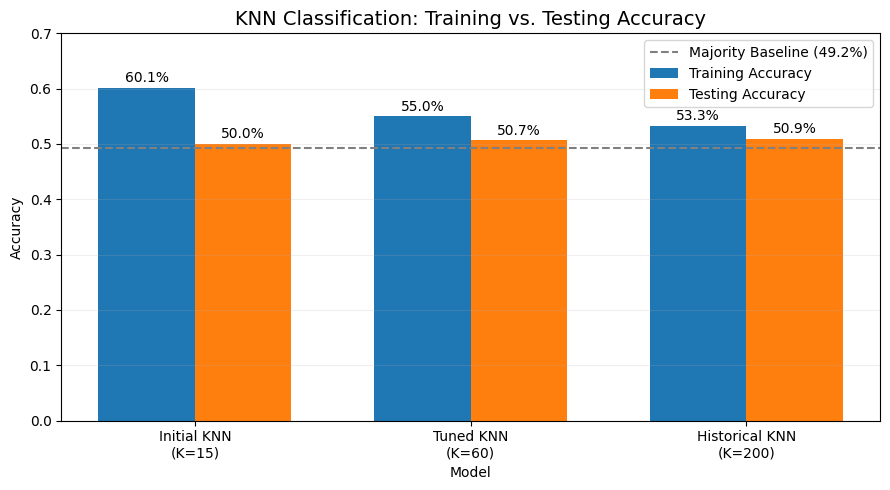

,Model,Training Accuracy,Testing Accuracy,Generalization Gap
0,Initial KNN\n(K=15),0.6012,0.5001,0.1011
1,Tuned KNN\n(K=60),0.5499,0.5065,0.0434
2,Historical KNN\n(K=200),0.5327,0.5090,0.0237


In [33]:
# Compare classification model accuracy
model_comparison = pd.DataFrame({
    "Model": [
        "Initial KNN\n(K=15)",
        "Tuned KNN\n(K=60)",
        "Historical KNN\n(K=200)"
    ],
    "Training Accuracy": [
        accuracy_score(y_train_cls, train_cls_pred),
        accuracy_score(y_train_cls, best_train_pred),
        accuracy_score(y_adv_train, advanced_train_pred)
    ],
    "Testing Accuracy": [
        accuracy_score(y_test_cls, test_cls_pred),
        accuracy_score(y_test_cls, best_test_pred),
        accuracy_score(y_adv_test, advanced_test_pred)
    ]
})

# Calculate generalization gap
model_comparison["Generalization Gap"] = (
    model_comparison["Training Accuracy"]
    - model_comparison["Testing Accuracy"]
)

# Plot grouped bars
x = np.arange(len(model_comparison))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

train_bars = ax.bar(
    x - width / 2,
    model_comparison["Training Accuracy"],
    width,
    label="Training Accuracy"
)

test_bars = ax.bar(
    x + width / 2,
    model_comparison["Testing Accuracy"],
    width,
    label="Testing Accuracy"
)

# Majority-class benchmark
ax.axhline(
    y=baseline_accuracy,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label=f"Majority Baseline ({baseline_accuracy:.1%})"
)

# Add accuracy labels
for bars in [train_bars, test_bars]:
    for bar in bars:
        height = bar.get_height()

        ax.annotate(
            f"{height:.1%}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            fontsize=10
        )

ax.set_title(
    "KNN Classification: Training vs. Testing Accuracy",
    fontsize=14
)

ax.set_ylabel("Accuracy")
ax.set_xlabel("Model")
ax.set_xticks(x)
ax.set_xticklabels(model_comparison["Model"])
ax.set_ylim(0, 0.70)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

# Save high-resolution figure for Milestone Two
Path("../figures").mkdir(parents=True, exist_ok=True)

plt.savefig(
    "../figures/week08_knn_classification_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display supporting table
display(model_comparison.round(4))

## Final Conclusions

K-Nearest Neighbors was evaluated for NBA game-total regression
and Over/Under classification using multiple distance metrics,
neighbor counts, and feature sets.

Regression results showed that moneyline missingness differed
substantially between historical training games and recent test
games. Removing moneylines reduced test MAE from 26.65 to 14.25,
although the sportsbook benchmark remained more accurate at 14.14.

For classification, the initial KNN achieved 50.01% test accuracy
and 0.5020 ROC AUC. Cross-validation tuning improved ROC AUC to
0.5126, while increasing K reduced the training-testing gap.

A final model incorporating historical scoring trends, defensive
performance, and rest days achieved 50.90% test accuracy and
0.5114 ROC AUC. Although its generalization gap was smaller,
the additional features did not produce a meaningful increase
in predictive performance.

Overall, KNN provided limited improvements over simple benchmarks.
The results highlight the importance of feature availability,
chronological validation, and model complexity. Because some
model changes were motivated by examining test-set performance,
the final comparisons should be interpreted as exploratory.